# Processing of UAWOS ZondAreo WPR payload data
## Authors: Peter Bauer-Gottwein (pbg@ign.ku.dk)

# Preliminaries
This jupyter notebook documents the data processing workflow for the UAWOS ZondAero WPR payload. We demonstrate the data processing workflow for one recent example from the Orco/Po Rivers. We only include basic Level-2 and Level-3 processing steps. All necessary Level-1 data, auxiliary data and code files to run this notebook are included in a folder "WPR_processing_example", which is distributed with this notebook and is expected to sit in the directory from which this notebook is run. The WPR_processing_example folder also contains a listing of the UAWOS python environment and a corresponding .yaml file. Please install this environment (e.g. using conda) prior to running the notebook. 

# Level 1 data
A WPR survey consists of at least one cross section flight across the river. Typically there is one individual set of files for each cross section. Each flight may contain multiple crossings of the river, which have to be separated and overlaid in data processing. The standard case is that the drone crosses the river twice, i.e. forth and back.

The following files (with acquisition UTC time stamps in the file name) will be available for each WPR cross section flight:

* A *-position.csv file (e.g. 2025-04-10-13-37-22-position.csv in our example), which contains the drone positioning information from SkyHub. This file also contains a column "zGPR:Trace", which links each GPR trace with its corresponding time stamp and drone position.
* A *-gpr.sgy file (e.g. 2025-04-10-13-37-22-gpr.sgy in our example), which contains the full trace output (i.e. radargram) from the ZondAero GPR system.

# Auxiliary data
The following auxiliary data files and items are required to process an LX80 dataset:
* A cross section shapefile (chain_XSline_Cavour_utm.shp in our case). This shapefile should be in the target projection of the survey (EPSG:32632) in our case. It should be a point shapefile with points every 0.2 m along the cross section line. Depending on the size of the river etc., other point spacings may be used. You can produce this file from any river cross section line shapefile, for instance using the QGIS plugin "QChainage". The usual convention is that the cross section coordinate should increase from the left back to the right bank of the river (left and right are defined looking downstream), and that coordinate 0 should be at the intersection with the river centerline. If ground truth data is available, the cross section line may be placed along the ground truth points, to facilitate direct comparison between WPR and ground truth data.
* A geotiff file giving the elevation of the target geoid above the WGS84 ellipsoid at suitable spatial resolution (e.g. 10m) In our example, we use ITALGEO05 as the geoid and the file is ITALGEO2005_Orco_negative.tif.
* The EPSG code for the target projection (EPSG:32632 in our case)
* The EPSG code for the target geoid (ITALGEO05 in our case)
* The identifier of the chainage field in the attribute table of the cross section shapefile. If you use QChainage, the identifier will be "cngmeters"
* The WSE of the river (relative to the chosen geoid or WGS84) at the cross section. This is required to convert depth measured by the WPR into riverbed elevation.

# Processing
## 1. Preparing the cross section shapefile
This can be done in QGIS. Go through the following steps:
1. Load the *position.csv file into QGIS as a comma-separated text layer.
2. Create a new line shapefile
3. Create a new shape feature for the reference cross section line
4. Chop up the line into equally spaced points (e.g. 0.2 m), using for instance QGIS plugin "QChainage"
5. Adjust the "cngmeters" field to ensure coordinate zero is at the river centerline.

## 2. Fligth Pre-Processing
First, let's import all required packages:

In [1]:
import os
my_path = r'h:\UAWOS\uawos_data_processing' + os.sep + 'ZAero_processing_example'

from UAWOS_ZAero_flight import UAWOS_ZAero_flight

We provide inputs for auxiliary data and flight data. The flight data block can be copied as many times as there are profile flights in the survey:

In [2]:
Orco_general_attributes = dict()

Orco_general_attributes['xy_EPSG'] = 'EPSG:32632'
Orco_general_attributes['z_EPSG'] = 'ITALGEO05'
Orco_general_attributes['geoid_tiff'] = my_path + os.sep + 'ITALGEO2005_Orco_negative.tif'
Orco_general_attributes['chainage_field'] = 'cngmeter'

Orco_1_attributes = Orco_general_attributes.copy()

Orco_1_attributes['name_posfile'] = my_path + os.sep + '2025-04-10-13-37-22-position.csv'
Orco_1_attributes['name_segyfile'] = my_path + os.sep + '2025-04-10-13-37-22-gpr.sgy'
Orco_1_attributes['name_secfile'] = my_path + os.sep + '2025-04-10-13-37-22_sections.xlsx'# This will be created during preprocessing, pls see below
Orco_1_attributes['name_ppkfile'] = r''# if RTK was off during flight, the path to a corresponding ppk file that contains the relevant time stamp range can be provided here
Orco_1_attributes['refline_file'] = my_path + os.sep + 'chain_XSline_Cavour_utm.shp'
Orco_1_attributes['in_situ_L3'] = r''
Orco_1_attributes['WSE'] = 176.02
Orco_1_attributes['cfreq'] = 150 # Antenna frequency. ZondAeroLF has 100, 150 and 300 MHz
Orco_1_attributes['dir'] = 'parallel' # Antenna orientation wrt to flow direction. Parallel is default.
Orco_1_attributes['RTK_on'] = True
Orco_1_attributes['gain_power'] = 3 # These are parameters for the radargram visulization
Orco_1_attributes['gain_lt'] = 0.2 # These are parameters for the radargram visulization
Orco_1_attributes['gain_ut'] = 3 # These are parameters for the radargram visulization
Orco_1_attributes['CL_dist_threshold'] = 100 
Orco_1_attributes['L2_output'] = my_path + os.sep + r'Level_2\2025-04-10-13-37-22.csv'
Orco_1_attributes['L3_output'] = my_path + os.sep + r'Level_3\2025-04-10-13-37-22.csv'
Orco_1_attributes['gain_power'] = 3 # These are parameters for the radargram visulization
Orco_1_attributes['gain_lt'] = 0.2 # These are parameters for the radargram visulization
Orco_1_attributes['gain_ut'] = 3 # These are parameters for the radargram visulization

Orco_1 = UAWOS_ZAero_flight(Orco_1_attributes)

UAWOS Zond Areo LF flight class constructor


We now reference the data to the reference line and plot the drone elevation and the drone cross section coordinate vs the trace number to understand when the cross section flights start and end:

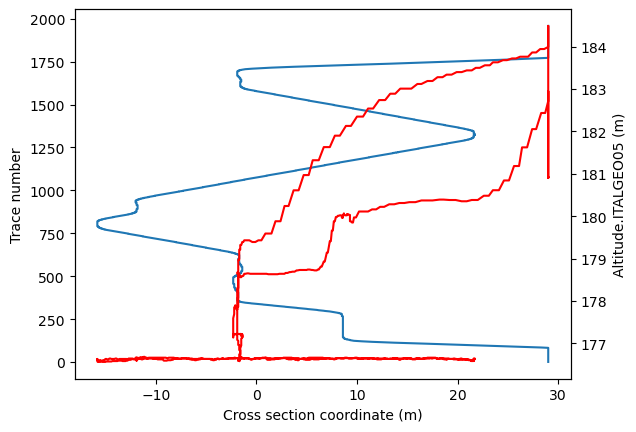

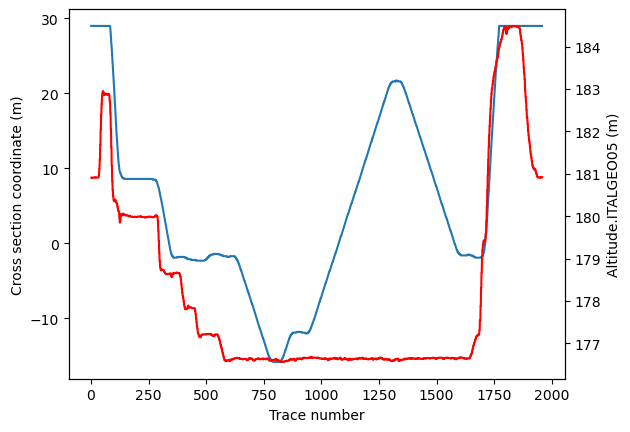

In [3]:
Orco_1 = Orco_1.process_WPR_flight()
Orco_1.plot_Tnum_Alt_vs_XScoord()
Orco_1.plot_XScoord_Alt_vs_Tnum()

From the plots it is clear that the cross section flight starts at around trace number 620 (low and constant altitude, uniform movement in cross section direction starts). At trace number 790, the drone reaches the end of the line. At trace number 820, the next crossing starts. Around trace number 900, the drone turns around (a maneuver that helps with efficient navigation and flight control) and continues. The drone reaches the other shore around trace number 1300 and turns around. The last part of the cross section flight from the shore to the midpoint is between trace numbers 1340 and 1600. This information is written into a "sections" excel file, which has a very simple format and can be seen in the "WPR processing example" folder (2025-04-10-13-37-22_sections.xlsx). We can now make a quick graphical check to ensure that start and end traces were correctly identified:

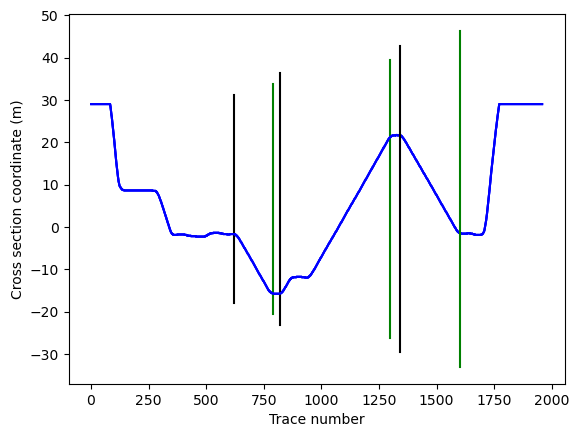

In [4]:
Orco_1.plot_sections()

We now identify the WSE from the RTK altitude and range to water surface during one of the cross section flights:

In [5]:
Orco_1.find_WSE()

Mean altitude, section  1 176.62999923706056
Mean range, section  1 0.4
WSE section  1 176.01999923706055
Mean altitude, section  2 176.62999923706056
Mean range, section  2 0.4
WSE section  2 176.01999923706055
Mean altitude, section  3 176.64999923706054
Mean range, section  3 0.41
WSE section  3 176.02999923706054


This is consistent with the expectation, as WPR flights are normally operated at 40 cm above the water surface.

## 3. Main Processing
We are now ready to perform the main processing of the WPR flight.

In [6]:
%matplotlib Qt
Orco_1.process_WPR_data()

Sampling rate:  0.714
Number of traces in dataset:  1958
Number of samples in each trace:  512
Please pick a rough lower bound on the bathymetry range by right-clicking your mouse, and clicking the middle for the ending:
Please manual updating by right-clicking your mouse, and clicking the middle for the ending:
Please pick a rough lower bound on the bathymetry range by right-clicking your mouse, and clicking the middle for the ending:
Please manual updating by right-clicking your mouse, and clicking the middle for the ending:


H:\UAWOS\uawos_data_processing\revision_10_25\UAWOS_ZAero_flight.py:278: UserWarning: The input coordinates to pcolor are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolor.
  plt.pcolor(XXv, YYv, gndata, vmin=np.percentile(gndata, color_lower_percentile), vmax=np.percentile(gndata, color_upper_percentile))


Please pick a rough lower bound on the bathymetry range by right-clicking your mouse, and clicking the middle for the ending:
Please manual updating by right-clicking your mouse, and clicking the middle for the ending:


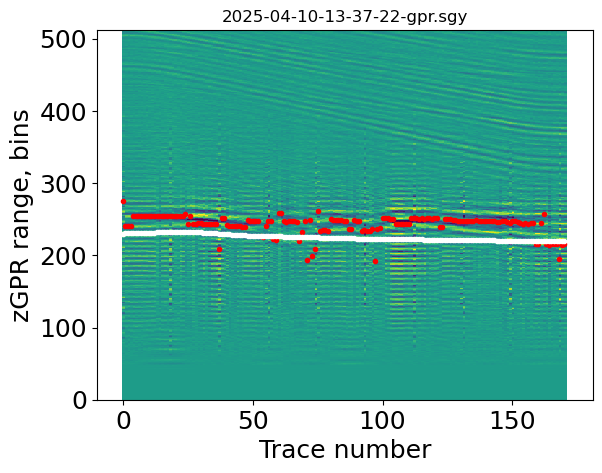

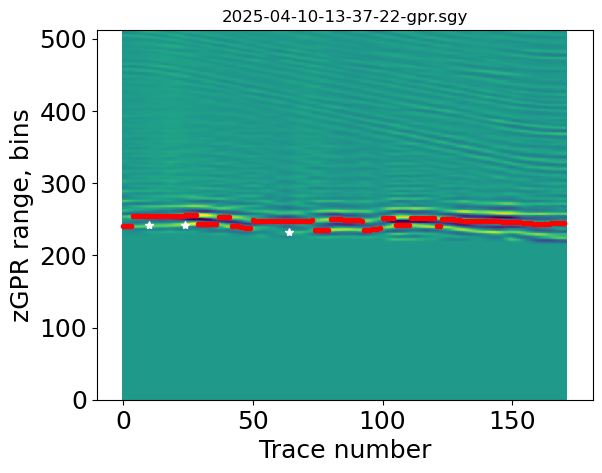

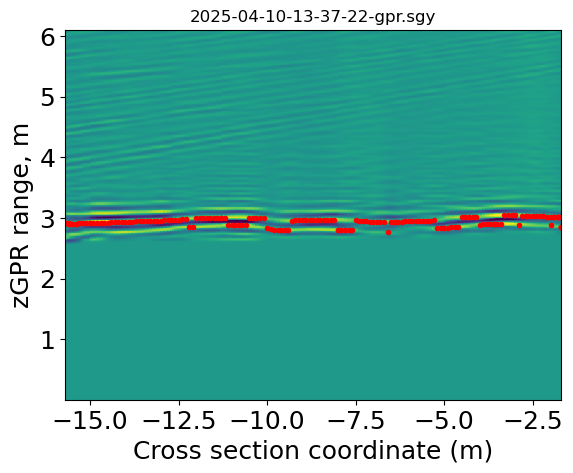

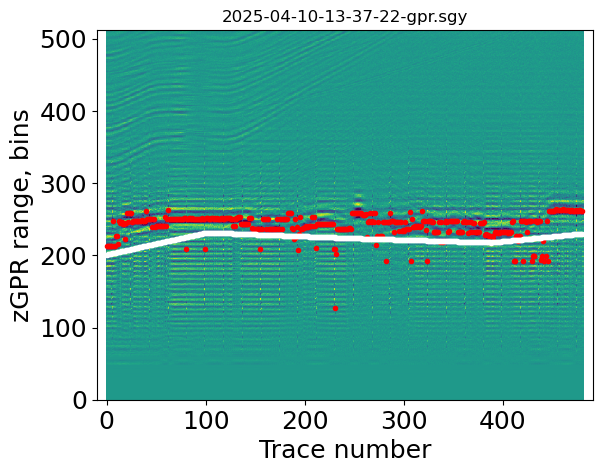

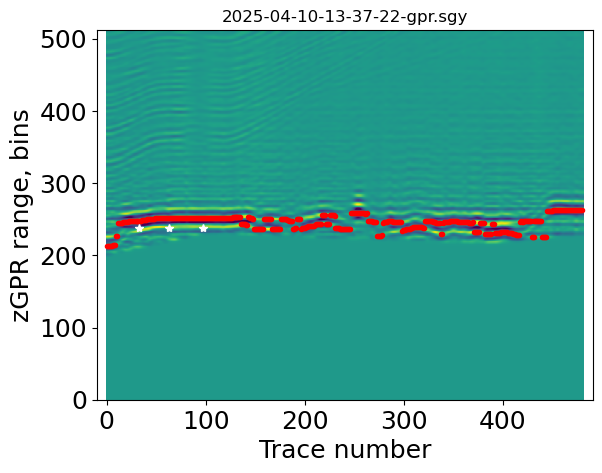

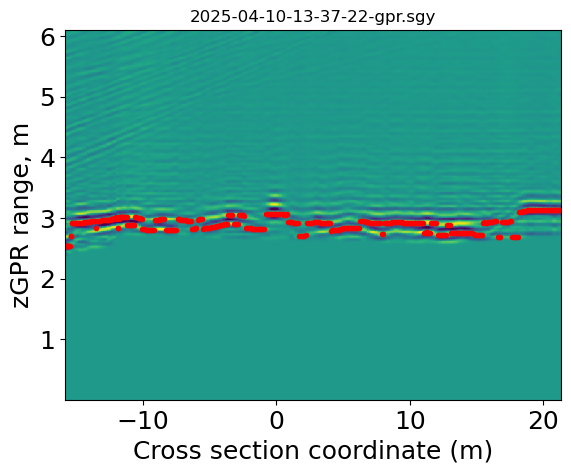

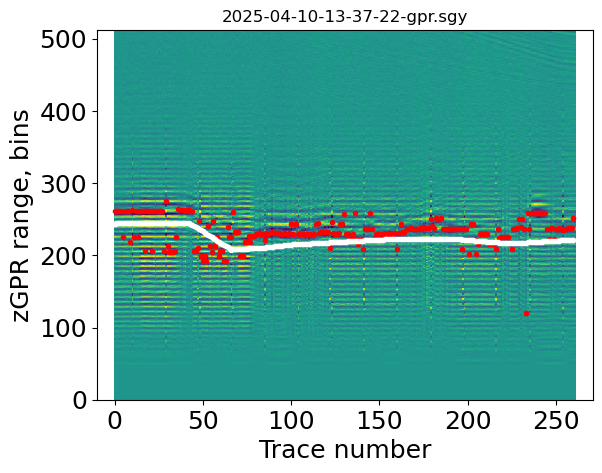

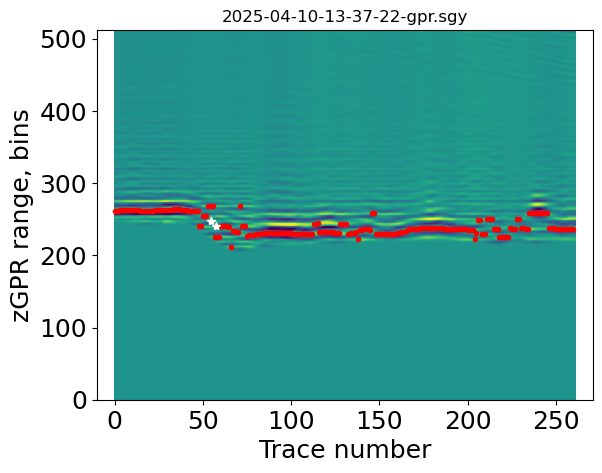

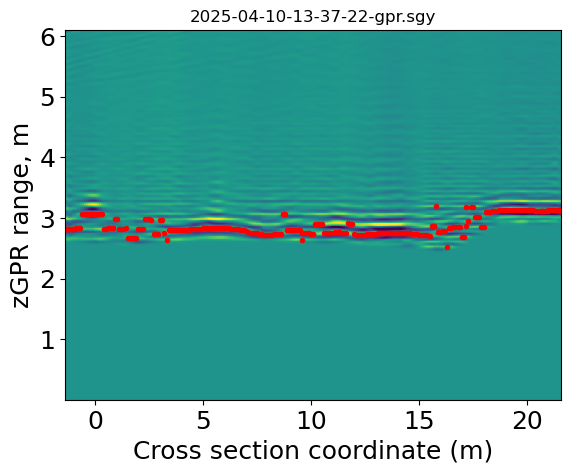

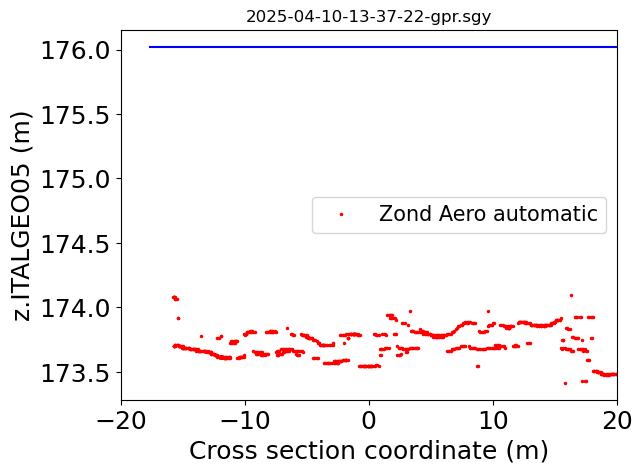

In [7]:
%matplotlib module://matplotlib_inline.backend_inline
Orco_1.plot_results([-20,20])

In [8]:
if not os.path.exists(my_path + os.sep + 'Level_2'):
    os.makedirs(my_path + os.sep + 'Level_2')
if not os.path.exists(my_path + os.sep + 'Level_3'):
    os.makedirs(my_path + os.sep + 'Level_3')
Orco_1.L2_L3_generation()

H:\UAWOS\uawos_data_processing\revision_10_25\UAWOS_ZAero_flight.py:338: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  XS_L3_auto = pd.concat([XS_L3_auto, df], axis=0)
